#### Histogram = Bar chart for continuous (numerical) data
* It tells you:
   * How often values appear
   * Which ranges have more or fewer data points
  * Suppose these are students’ marks:
35, 40, 42, 45, 48, 50, 55, 60, 62, 65, 70

* We create ranges (bins):

30–39
40–49
50–59
60–69
70–79

* Then we count how many marks fall in each range and draw bars.
* Why Histograms Are Useful : Histograms help you understand:
  * Where most data lies
  * Whether data is normal, skewed, or uniform
  * Spread of the data

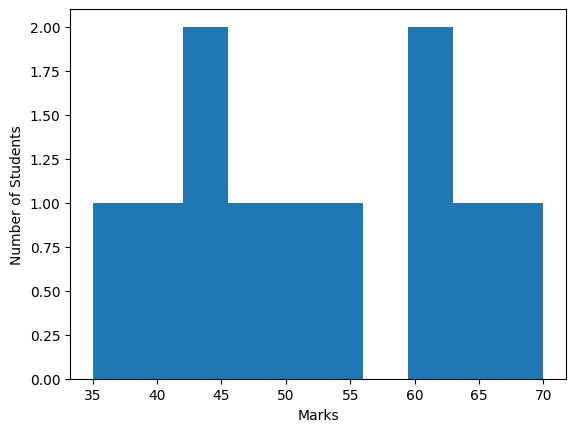

In [4]:
import matplotlib.pyplot as plt

data = [35,40,42,45,48,50,55,60,62,65,70]
plt.hist(data, bins=10)
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()

In [5]:
import pandas as pd

# 3 sample datasets
df = pd.DataFrame({
    "symmetric": [10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
    "right_skewed": [10, 11, 12, 13, 14, 15, 16, 17, 18, 100],   # one big outlier
    "left_skewed": [1, 50, 51, 52, 53, 54, 55, 56, 57, 58]       # one small outlier
})

# skewness in pandas
print("Skewness:")
print(df.skew())

# also useful: mean and median
print("\nMean:")
print(df.mean())

print("\nMedian:")
print(df.median())

Skewness:
symmetric       0.000000
right_skewed    3.109452
left_skewed    -3.025780
dtype: float64

Mean:
symmetric       14.5
right_skewed    22.6
left_skewed     48.7
dtype: float64

Median:
symmetric       14.5
right_skewed    14.5
left_skewed     53.5
dtype: float64


In [30]:
import os
os.getcwd()

'C:\\Users\\vikas.karanth'

2) Basic Log Transform (works only for all values > 0)

In [6]:
import pandas as pd
import numpy as np

s = pd.Series([5, 8, 10, 12, 15, 20, 50, 200], name="usage")

print("Original skew:", s.skew())

s_log = np.log(s)
print("Log skew:", s_log.skew())

Original skew: 2.5949856774119358
Log skew: 1.30446596607795


In [ ]:
s = pd.Series([0, 1, 2, 3, 5, 8, 13, 21, 100], name="hits")

print("Original skew:", s.skew())

s_log1p = np.log1p(s)
print("log1p skew:", s_log1p.skew())

In [7]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "MonthlyusageGb": [0, 2, 4, 5, 7, 10, 15, 18, 40, 120]
})

df["MonthlyusageGb_log"] = np.log1p(df["MonthlyusageGb"])

print(df)
print("Skew before:", df["MonthlyusageGb"].skew())
print("Skew after :", df["MonthlyusageGb_log"].skew())

   MonthlyusageGb  MonthlyusageGb_log
0               0            0.000000
1               2            1.098612
2               4            1.609438
3               5            1.791759
4               7            2.079442
5              10            2.397895
6              15            2.772589
7              18            2.944439
8              40            3.713572
9             120            4.795791
Skew before: 2.6382737544708297
Skew after : 0.19058501786921295


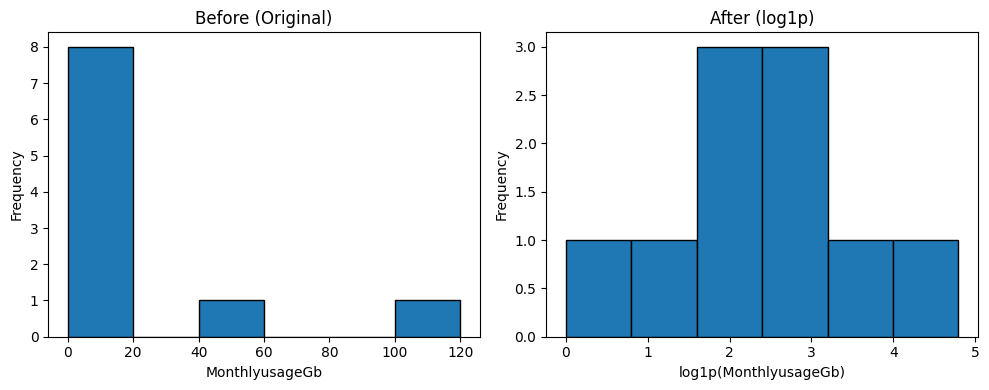

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

df["MonthlyusageGb"].plot(kind="hist", bins=6, edgecolor="black", ax=ax[0], title="Before (Original)")
df["MonthlyusageGb_log"].plot(kind="hist", bins=6, edgecolor="black", ax=ax[1], title="After (log1p)")

ax[0].set_xlabel("MonthlyusageGb")
ax[1].set_xlabel("log1p(MonthlyusageGb)")
plt.tight_layout()
plt.show()

In [ ]:
6) What if you have Negative Values?
Log doesn’t work with negatives. You have 3 common options:
Option A: Shift then log (simple, common)
Add a constant to make everything positive.

In [9]:
s = pd.Series([-5, -2, 0, 1, 3, 10], name="profit")

shift = 1 - s.min()   # makes min become 1
s_shift_log = np.log(s + shift)

print("Shift used:", shift)
print("Original skew:", s.skew())
print("Shift+log skew:", s_shift_log.skew())

Shift used: 6
Original skew: 0.9582773111509815
Shift+log skew: -1.1902882277201985


In [ ]:
Handling Skewness 
1️⃣ Log Transformation
🔹 What it is
A transformation that compresses large values more than small ones using logarithms.
Mathematically:
y = log(x)

🔹 Why it works

Reduces effect of very large outliers
Makes right‑skewed data more symmetric
Stabilizes variance


🔹 When to use
✅ Strong right‑skewed data
✅ Data with large value gaps
✅ Values must be positive
Examples:

Salary
Revenue
File size
Monthly usage

🔹 How to apply (Pandas)
import pandas as pd
import numpy as np

data = pd.Series([5, 8, 10, 12, 15, 20, 50, 200])

log_data = np.log(data)
print(log_data.skew())


✅ Safer version (handles zero):
Pythonlog_data = np.log1p(data)   # log(1 + x)Show more lines

2️⃣ Square Root Transformation
🔹 What it is
Applies the square root to each value:
y=sqrt(x)

🔹 Why it works

Mildly reduces large values
Less aggressive than log
Easy to interpret

🔹 When to use
✅ Moderate skewness
✅ Counts & frequencies (events per day, errors)

🔹 How to apply
sqrt_data = np.sqrt(data)
print(sqrt_data.skew())


3️⃣ Power Transformation (General Idea)
🔹 What it is
Raise data to a power to change distribution shape.
Examples:

Square
Cube
Reciprocal

🔹 Why it works
Allows custom control over skew direction.

🔹 When to use

Data typeTransformation
Right‑skewedlog(x), sqrt(x)
Left‑skewedsquare(x), cube(x)

🔹 How to apply
✅ Left‑skew example:
Pythonleft_skewed = pd.Series([90, 92, 94, 96, 98, 100])
fixed = left_skewed ** 2
print(fixed.skew())Show more lines

4️⃣ Winsorization (Outlier Capping)
🔹 What it is
Limits extreme values to a percentile boundary
(does not remove data)

🔹 Why it works

Removes extreme influence of outliers
Keeps dataset size same
from scipy.stats.mstats import winsorize

wins_data = pd.Series(winsorize(data, limits=[0.05, 0.05]))
print(wins_data.skew())

🔹 When to use
✅ Skewness caused by few extreme values
✅ Cannot delete rows (financial / audit data)

🔹 How to apply

✅ Here:

Top 5% capped
Bottom 5% capped



In [10]:
import pandas as pd
import numpy as np

data = pd.Series([2, 3, 4, 5, 7, 10, 20, 50, 120], name="usage")

print("Original skew:", data.skew())

Original skew: 2.300986580026175


In [11]:
from scipy.stats import boxcox

# boxcox returns transformed data AND lambda
data_bc, best_lambda = boxcox(data)

data_bc = pd.Series(data_bc, name="usage_boxcox")

print("Best lambda:", best_lambda)
print("Skew after Box-Cox:", data_bc.skew())

Best lambda: -0.3219322737329643
Skew after Box-Cox: 0.20029355370814556


In [ ]:
df = pd.DataFrame({
    "original": data,
    "boxcox": data_bc
})

print(df.head())

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10,4))

df["original"].plot(kind="hist", bins=6, edgecolor="black",
                    title="Before (Original)", ax=ax[0])

df["boxcox"].plot(kind="hist", bins=6, edgecolor="black",
                  title="After (Box-Cox)", ax=ax[1])

plt.tight_layout()
plt.show()

### Handling negetive skewness 
#### Reflection + log transformation
#### Reflection + sq.root transformation
#### Reflection + Box-Cox transformation
#### power Transformation

#### Reflection method:
#### Reflection method formula:x = max(x) +1-x

In [13]:
data=[2,30,32,35,37,40,42,45]
df=pd.DataFrame(data,columns=['values'])
max_value=df['values'].max()
df['reflected']=max_value+1-df['values']
df['log_transformed']=np.log(df['reflected'])
print(df)

   values  reflected  log_transformed
0       2         44         3.784190
1      30         16         2.772589
2      32         14         2.639057
3      35         11         2.397895
4      37          9         2.197225
5      40          6         1.791759
6      42          4         1.386294
7      45          1         0.000000


#correlation
''' measures the strength and direction of the relationship between two variablea '''
How on variable changes then how another variable changes.
Positive Correlation (+ve correlation)
✅ What it means
* When one variable increases, the other also increases
* (or when one decreases, the other decreases).
📈 They move in the same direction.

✅ Examples

* Hours studied ↑ → Exam score ↑
* Temperature ↑ → Ice‑cream sales ↑
* Experience ↑ → Salary ↑ (often)

 Negative Correlation (−ve correlation)
✅ What it means
* When one variable increases, the other decreases.
📉 They move in opposite directions.

✅ Examples

* Price ↑ → Demand ↓
* Speed ↑ → Travel time ↓
* More screen time ↑ → Battery life ↓
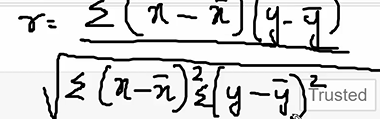


In [16]:
data=pd.DataFrame({'yoe':[2,4,6,8],
                  'sal':[50,60,70,80]})
data.corr()

,yoe,sal
yoe,1.0,1.0
sal,1.0,1.0


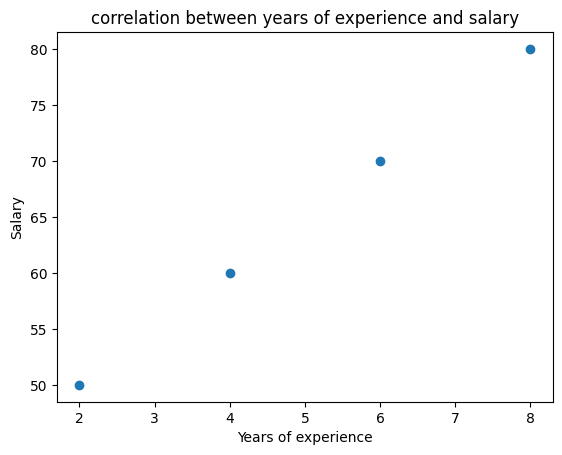

In [17]:
plt.scatter(data['yoe'],data['sal'])
plt.xlabel("Years of experience")
plt.ylabel('Salary')
plt.title("correlation between years of experience and salary")
plt.show()

In [27]:
data=pd.DataFrame({'age':[25,30,35],

                  'income':[30000,35000,40000],

                  'spending':[20000,25000,30000]})
 

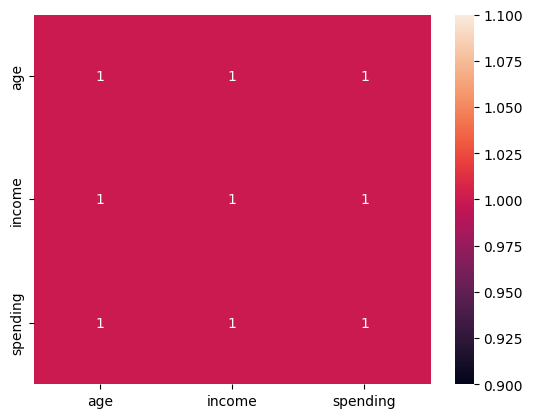

In [28]:
import seaborn as sns
sns.heatmap(data.corr(),annot=True)
plt.show()

In [ ]:
plt.scatter(data['yoe'],data['sal'])
plt.xlabel("Years of experience")
plt.ylabel('Salary')
plt.title("correlation between years of experience and salary")
plt.show()

In [22]:
#Positive Correlation (+ve correlation)

df = pd.DataFrame({
    "Hours_Studied": [2, 4, 6, 8, 10],
    "Score": [40, 55, 65, 78, 90]
})

print(df.corr())

               Hours_Studied     Score
Hours_Studied       1.000000  0.998582
Score               0.998582  1.000000


In [23]:
# Negative Correlation (−ve correlation)
df = pd.DataFrame({
    "Price": [10, 20, 30, 40, 50],
    "Demand": [100, 80, 60, 40, 20]
})

print(df.corr())

        Price  Demand
Price     1.0    -1.0
Demand   -1.0     1.0


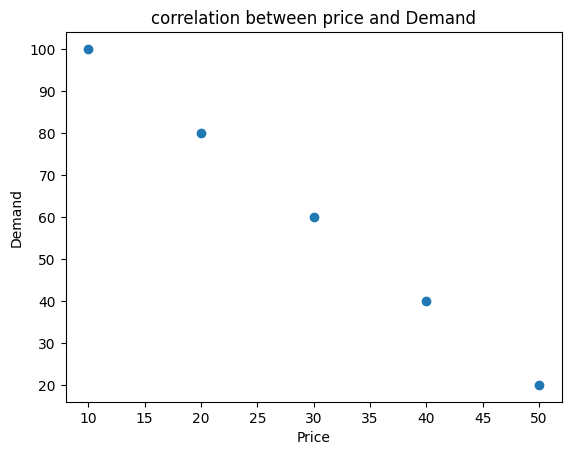

In [26]:
plt.scatter(df['Price'],df['Demand'])
plt.xlabel("Price")
plt.ylabel('Demand')
plt.title("correlation between price and Demand")
plt.show()